# First-stage feature distributions by class

This notebook plots one combined set of violin distributions for every annotated cell listed in the first-stage train, validation, and test splits. Matrix values are loaded directly from `Data/Raw/beach_all`.

Features: `r` = red, `g` = green, `b` = blue, `s` = slope, and `d` = elevation. For every cell and feature, the mean and standard deviation are calculated from its finite pixels. NaN, infinite, and exact `-999` values are excluded. Each split violin shows the distribution of cell means on its darker left half and cell standard deviations on its lighter right half. No cell sampling cap is applied.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (
    (PROJECT_ROOT / "Source").is_dir()
    and (PROJECT_ROOT / "Notebooks").is_dir()
):
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (
    (PROJECT_ROOT / "Source").is_dir()
    and (PROJECT_ROOT / "Notebooks").is_dir()
):
    raise RuntimeError(
        "Could not locate project root containing Source and Notebooks."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Source.beach_dataset import (
    FEATURE_SUFFIXES,
    load_cell_array,
    make_class_mapping,
    read_class_name_mapping,
    read_split_csv,
)

/Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
CELL_DATA_ROOT = PROJECT_ROOT / "Data" / "Raw" / "beach_all"
CLASS_MAPPING_PATH = PROJECT_ROOT / "Data" / "Raw" / "Classes.xlsx"
SPLIT_PATH = PROJECT_ROOT / "Data" / "Preprocessed" / "dataset_splits.csv"

FEATURE_LABELS = {
    "r": "red channel (r)",
    "g": "green channel (g)",
    "b": "blue channel (b)",
    "s": "slope (s)",
    "d": "elevation (d)",
}
FEATURE_COLORS = {
    "r": "#d62728",
    "g": "#2ca02c",
    "b": "#1f77b4",
    "s": "#9467bd",
    "d": "#ff7f0e",
}
MEAN_AXIS_LABELS = {
    "r": "Cell mean",
    "g": "Cell mean",
    "b": "Cell mean",
    "s": "Cell mean (°)",
    "d": "Cell mean (m a.s.l.)",
}
STD_AXIS_LABELS = {
    "r": "Cell standard deviation",
    "g": "Cell standard deviation",
    "b": "Cell standard deviation",
    "s": "Cell standard deviation (°)",
    "d": "Cell standard deviation (m)",
}
SUBPLOT_TITLE_SIZE = 13
AXIS_LABEL_SIZE = 12
TICK_LABEL_SIZE = 11
FIGURE_TITLE_SIZE = 15
EXPECTED_SPLITS = {"train", "validation", "test"}

print(f"Cell data: {CELL_DATA_ROOT}")
print(f"Split file: {SPLIT_PATH}")

Cell data: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/pmaciag-volume-beach/Data/Raw/beach_all
Split file: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/pmaciag-volume-beach/Data/Preprocessed/dataset_splits.csv


In [3]:
if not CELL_DATA_ROOT.exists():
    raise FileNotFoundError(f"Cell data directory not found: {CELL_DATA_ROOT}")

all_labeled_data = read_split_csv(SPLIT_PATH)
if "split" not in all_labeled_data.columns:
    raise ValueError(f"Split column is missing from {SPLIT_PATH}")
actual_splits = set(all_labeled_data["split"].astype(str))
if actual_splits != EXPECTED_SPLITS:
    raise ValueError(f"Expected splits {sorted(EXPECTED_SPLITS)}, got {sorted(actual_splits)}")
if all_labeled_data.duplicated(["date", "cell_id"]).any():
    raise ValueError("Duplicate date/cell_id entries found in the combined split file.")

class_to_idx = make_class_mapping(all_labeled_data)
class_name_by_code = read_class_name_mapping(CLASS_MAPPING_PATH, class_to_idx.keys())
class_codes = [code for code, _ in sorted(class_to_idx.items(), key=lambda item: item[1])]
class_labels = [
    f"{code}: {class_name_by_code.get(code, f'class_{code}')}"
    for code in class_codes
]
display(all_labeled_data.groupby("split").size().rename("cells").to_frame())
display(all_labeled_data.groupby("class").size().rename("cells").to_frame())

,cells
split,
test,1219
train,5685
validation,1218


,cells
class,
0,117
1,2385
2,1447
3,665
4,706
5,645
6,536
7,856
8,723


In [4]:
def collect_cell_statistics(frame):
    buckets = {
        feature: {
            class_code: {"mean": [], "std": []}
            for class_code in class_codes
        }
        for feature in FEATURE_SUFFIXES
    }
    missing_cells = 0
    missing_values_by_feature = {feature: 0 for feature in FEATURE_SUFFIXES}
    rows = frame[["date", "cell_id", "class"]].itertuples(index=False, name=None)
    for date, cell_id, class_code in tqdm(rows, total=len(frame), desc="Loading labeled cells"):
        array = load_cell_array(CELL_DATA_ROOT, date, cell_id, FEATURE_SUFFIXES)
        missing_mask = ~np.isfinite(array)
        if missing_mask.any():
            missing_cells += 1
        class_code = str(class_code)
        for feature_index, feature in enumerate(FEATURE_SUFFIXES):
            values = array[feature_index].reshape(-1)
            finite_mask = np.isfinite(values)
            missing_values_by_feature[feature] += int((~finite_mask).sum())
            finite_values = values[finite_mask]
            if finite_values.size:
                buckets[feature][class_code]["mean"].append(float(np.mean(finite_values)))
                buckets[feature][class_code]["std"].append(float(np.std(finite_values)))
    missing_summary = {
        "cells": missing_cells,
        "values": sum(missing_values_by_feature.values()),
        "by_feature": missing_values_by_feature,
    }
    return buckets, missing_summary


def lighten_color(color, amount=0.6):
    rgb = np.asarray(mcolors.to_rgb(color))
    return tuple(rgb + (1.0 - rgb) * amount)


def draw_half_violin(axis, values, position, side, color):
    if not values:
        return
    values = np.asarray(values, dtype=float)
    if values.size >= 2 and np.ptp(values) > 0:
        parts = axis.violinplot(
            [values],
            positions=[position],
            widths=0.8,
            showmeans=False,
            showmedians=False,
            showextrema=False,
        )
        body = parts["bodies"][0]
        for path in body.get_paths():
            vertices = path.vertices
            if side == "left":
                vertices[:, 0] = np.minimum(vertices[:, 0], position)
            else:
                vertices[:, 0] = np.maximum(vertices[:, 0], position)
        body.set_facecolor(color)
        body.set_edgecolor("black")
        body.set_alpha(0.8)
    else:
        offset = -0.08 if side == "left" else 0.08
        axis.scatter(position + offset, values[0], color=color, edgecolor="black", s=18, zorder=3)

    median = float(np.median(values))
    x_min, x_max = (position - 0.32, position) if side == "left" else (position, position + 0.32)
    axis.hlines(median, x_min, x_max, color="black", linewidth=1.1, zorder=4)


def plot_combined_violins(buckets):
    fig, axes = plt.subplots(
        nrows=len(FEATURE_SUFFIXES),
        ncols=1,
        figsize=(max(12, len(class_codes) * 1.2), 3.2 * len(FEATURE_SUFFIXES)),
        sharex=True,
    )
    positions = np.arange(1, len(class_codes) + 1)
    for axis, feature in zip(axes, FEATURE_SUFFIXES):
        mean_axis = axis
        std_axis = axis.twinx()
        mean_color = FEATURE_COLORS[feature]
        std_color = lighten_color(mean_color)
        for position, class_code in zip(positions, class_codes):
            statistics = buckets[feature][class_code]
            draw_half_violin(mean_axis, statistics["mean"], position, "left", mean_color)
            draw_half_violin(std_axis, statistics["std"], position, "right", std_color)
        axis.set_title(
            FEATURE_LABELS[feature],
            fontsize=SUBPLOT_TITLE_SIZE,
            fontweight="bold",
        )
        axis.grid(axis="y", alpha=0.25)
        mean_axis.set_ylabel(
            MEAN_AXIS_LABELS[feature], color=mean_color, fontsize=AXIS_LABEL_SIZE
        )
        std_axis.set_ylabel(
            STD_AXIS_LABELS[feature], color=mean_color, fontsize=AXIS_LABEL_SIZE
        )
        mean_axis.tick_params(axis="y", labelcolor=mean_color, labelsize=TICK_LABEL_SIZE)
        std_axis.tick_params(axis="y", labelcolor=mean_color, labelsize=TICK_LABEL_SIZE)

    axes[-1].set_xticks(positions)
    axes[-1].set_xticklabels(
        class_labels, rotation=45, ha="right", fontsize=TICK_LABEL_SIZE
    )
    axes[-1].set_xlabel("Class", fontsize=AXIS_LABEL_SIZE)
    fig.suptitle(
        "Mean and Std statistics by class and channel\n"
        "Missing values excluded; left half of each violin - cell means, right - cell standard deviations",
        fontsize=FIGURE_TITLE_SIZE,
        y=1.01,
    )
    fig.tight_layout()
    return fig

Loading labeled cells: 100%|██████████| 8122/8122 [00:11<00:00, 723.52it/s]

Annotated cells with missing values: 65
Missing pixel-channel values: 10,134


,feature,missing_values
0,r,0
1,g,0
2,b,0
3,s,5074
4,d,5060


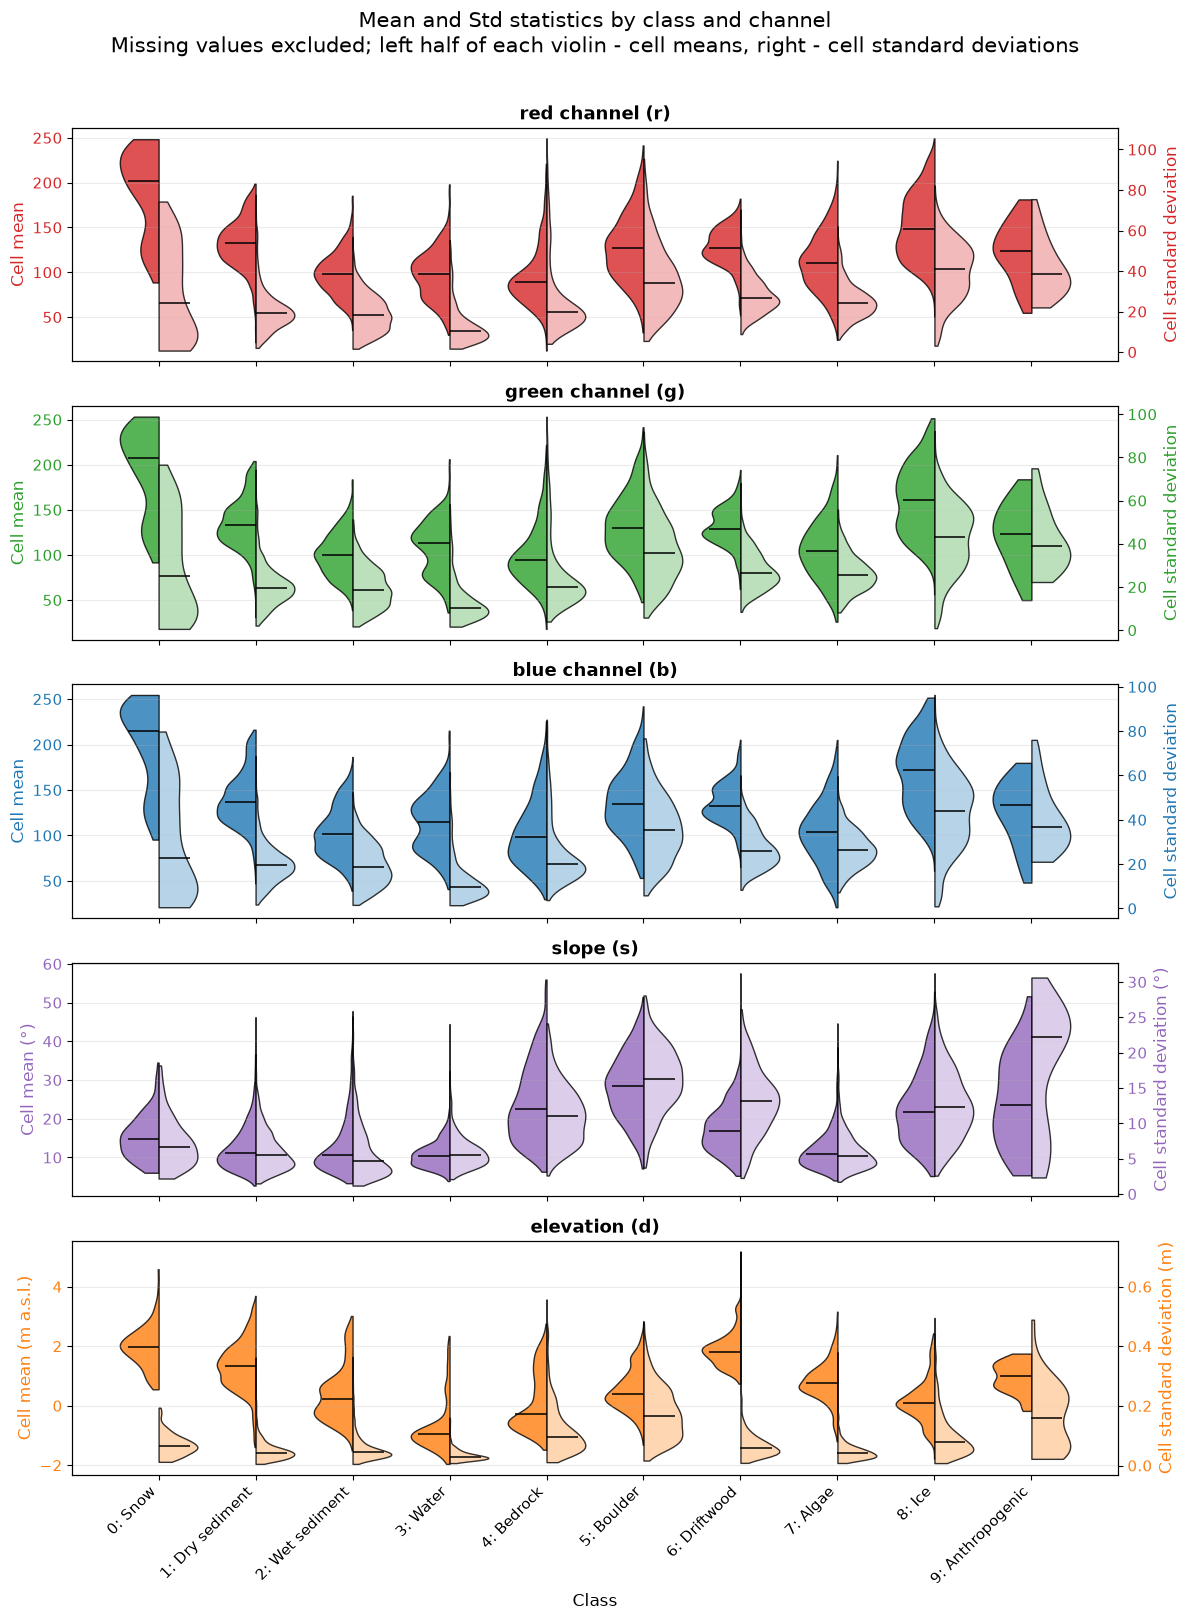

In [5]:
combined_buckets, missing_summary = collect_cell_statistics(all_labeled_data)
print(f"Annotated cells with missing values: {missing_summary['cells']:,}")
print(f"Missing pixel-channel values: {missing_summary['values']:,}")
display(
    pd.DataFrame({
        "feature": FEATURE_SUFFIXES,
        "missing_values": [missing_summary["by_feature"][feature] for feature in FEATURE_SUFFIXES],
    })
)
combined_figure = plot_combined_violins(combined_buckets)
plt.show()

In [6]:
OUTLIER_THRESHOLD = -900

# Exact -999 values are converted to NaN by load_cell_array and excluded from
# the violin plot. This report finds remaining finite values near -1000.
outlier_rows = []
rows = all_labeled_data[["split", "date", "cell_id", "class"]].itertuples(
    index=False,
    name=None,
)
for split, date, cell_id, class_code in tqdm(
    rows,
    total=len(all_labeled_data),
    desc="Checking slope/elevation outliers",
):
    array = load_cell_array(CELL_DATA_ROOT, date, cell_id, FEATURE_SUFFIXES)
    slope = array[FEATURE_SUFFIXES.index("s")]
    elevation = array[FEATURE_SUFFIXES.index("d")]
    slope_pixels = int((np.isfinite(slope) & (slope <= OUTLIER_THRESHOLD)).sum())
    elevation_pixels = int((np.isfinite(elevation) & (elevation <= OUTLIER_THRESHOLD)).sum())
    if slope_pixels or elevation_pixels:
        class_code = str(class_code)
        outlier_rows.append({
            "split": split,
            "date": date,
            "cell_id": cell_id,
            "class": class_code,
            "class_name": class_name_by_code.get(class_code, f"class_{class_code}"),
            "slope_outlier_pixels": slope_pixels,
            "elevation_outlier_pixels": elevation_pixels,
            "total_outlier_pixels": slope_pixels + elevation_pixels,
        })

outlier_cells = pd.DataFrame(outlier_rows)
slope_total = int(outlier_cells["slope_outlier_pixels"].sum()) if not outlier_cells.empty else 0
elevation_total = int(outlier_cells["elevation_outlier_pixels"].sum()) if not outlier_cells.empty else 0
print(f"Outlier threshold: <= {OUTLIER_THRESHOLD}")
print(f"Cells with slope/elevation outliers: {len(outlier_cells):,}")
print(f"Slope outlier pixels: {slope_total:,}")
print(f"Elevation outlier pixels: {elevation_total:,}")
print(f"Total outlier pixels: {slope_total + elevation_total:,}")
if not outlier_cells.empty:
    display(outlier_cells.sort_values(["date", "cell_id"]).reset_index(drop=True))
    print("Cell IDs:")
    print(", ".join(outlier_cells["cell_id"].astype(str).tolist()))

Checking slope/elevation outliers: 100%|██████████| 8122/8122 [00:09<00:00, 830.71it/s]

Outlier threshold: <= -900
Cells with slope/elevation outliers: 0
Slope outlier pixels: 0
Elevation outlier pixels: 0
Total outlier pixels: 0


In [7]:
# from concurrent.futures import ThreadPoolExecutor

# FULL_DATASET_SCAN_WORKERS = 4
# FULL_DATASET_SCAN_BATCH_SIZE = 1000


# def discover_complete_cell_ids(date_dir):
#     cell_ids = []
#     incomplete_cells = 0
#     for red_path in date_dir.glob("*r.txt"):
#         cell_id = red_path.name[:-len("r.txt")]
#         if all((date_dir / f"{cell_id}{feature}.txt").is_file() for feature in FEATURE_SUFFIXES):
#             cell_ids.append(cell_id)
#         else:
#             incomplete_cells += 1
#     return cell_ids, incomplete_cells


# def cell_contains_missing_values(date_dir, cell_id):
#     array = load_cell_array(CELL_DATA_ROOT, date_dir.name, cell_id, FEATURE_SUFFIXES)
#     return bool((~np.isfinite(array)).any())


# date_directories = sorted(path for path in CELL_DATA_ROOT.iterdir() if path.is_dir())
# total_complete_cells = 0
# total_incomplete_cells = 0
# total_cells_with_missing_values = 0

# with ThreadPoolExecutor(max_workers=FULL_DATASET_SCAN_WORKERS) as executor:
#     for date_index, date_dir in enumerate(date_directories, start=1):
#         cell_ids, incomplete_cells = discover_complete_cell_ids(date_dir)
#         date_missing_cells = 0
#         progress = tqdm(
#             total=len(cell_ids),
#             desc=f"Scanning {date_dir.name} ({date_index}/{len(date_directories)})",
#         )
#         for batch_start in range(0, len(cell_ids), FULL_DATASET_SCAN_BATCH_SIZE):
#             batch = cell_ids[batch_start:batch_start + FULL_DATASET_SCAN_BATCH_SIZE]
#             missing_flags = executor.map(
#                 lambda cell_id: cell_contains_missing_values(date_dir, cell_id),
#                 batch,
#             )
#             date_missing_cells += sum(missing_flags)
#             progress.update(len(batch))
#         progress.close()

#         total_complete_cells += len(cell_ids)
#         total_incomplete_cells += incomplete_cells
#         total_cells_with_missing_values += date_missing_cells
#         print(
#             f"{date_dir.name}: {date_missing_cells:,} of {len(cell_ids):,} complete cells "
#             "contain missing values"
#         )

# print(f"Complete cells scanned in the entire dataset: {total_complete_cells:,}")
# print(f"Incomplete cells skipped: {total_incomplete_cells:,}")
# print(
#     "Cells with missing values in the entire dataset: "
#     f"{total_cells_with_missing_values:,}"
# )